
# Titanic Data Analysis & Visualization


## 1) Import Libraries and Data

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", None)
plt.rcParams["figure.figsize"] = (8, 5)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

df = pd.read_csv("titanic.csv")
print("Shape:", df.shape)
df.head()

Shape: (891, 12)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


## 2) Initial Inspection

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 83.7 KB


In [5]:
# Count and percentage of missing values
missing = pd.DataFrame({
    "missing_count": df.isnull().sum(),
    "missing_%": (df.isnull().mean() * 100).round(2)
}).sort_values("missing_count", ascending=False)
missing[missing.missing_count > 0]

,missing_count,missing_%
Cabin,687,77.10
Age,177,19.87
Embarked,2,0.22


## 3) Data Cleaning


In [6]:
df_clean = df.copy()

# --- Duplicates ---
dups = df_clean.duplicated().sum()
print("Duplicate rows:", dups)
df_clean = df_clean.drop_duplicates()

# --- Age ---
df_clean["Age"] = df_clean.groupby(["Pclass", "Sex"])["Age"].transform(lambda s: s.fillna(s.median()))

# --- Embarked ---
df_clean["Embarked"] = df_clean["Embarked"].fillna(df_clean["Embarked"].mode()[0])

# --- Cabin ---
df_clean["HasCabin"] = df_clean["Cabin"].notnull().astype(int)
df_clean["Deck"] = df_clean["Cabin"].str[0].fillna("Unknown")
df_clean = df_clean.drop(columns="Cabin")

print("Remaining missing values:\n", df_clean.isnull().sum()[lambda s: s > 0])
print("Shape after cleaning:", df_clean.shape)

Duplicate rows: 0
Remaining missing values:
 Series([], dtype: int64)
Shape after cleaning: (891, 13)


## 4) Feature Engineering


In [7]:
df_clean["FamilySize"] = df_clean["SibSp"] + df_clean["Parch"] + 1
df_clean["IsAlone"] = (df_clean["FamilySize"] == 1).astype(int)

df_clean["Title"] = df_clean["Name"].str.extract(r",\s*([^\.]+)\.", expand=False).str.strip()
df_clean["Title"] = df_clean["Title"].replace({"Mlle": "Miss", "Ms": "Miss", "Mme": "Mrs"})
common = df_clean["Title"].value_counts()
df_clean["Title"] = df_clean["Title"].where(df_clean["Title"].isin(common[common >= 10].index), "Other")

df_clean["AgeGroup"] = pd.cut(df_clean["Age"], bins=[0, 12, 18, 35, 60, 100],
                              labels=["Child", "Teen", "Young Adult", "Adult", "Senior"])
df_clean[["Name", "FamilySize", "IsAlone", "Title", "AgeGroup"]].head()

,Name,FamilySize,IsAlone,Title,AgeGroup
0,"Braund, Mr. Owen Harris",2,0,Mr,Young Adult
1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",2,0,Mrs,Adult
2,"Heikkinen, Miss. Laina",1,1,Miss,Young Adult
3,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",2,0,Mrs,Young Adult
4,"Allen, Mr. William Henry",1,1,Mr,Young Adult


## 5) Descriptive Statistics

In [8]:
df_clean[["Age", "Fare", "SibSp", "Parch", "FamilySize"]].describe().round(2)

,Age,Fare,SibSp,Parch,FamilySize
count,891.00,891.00,891.00,891.00,891.00
mean,29.11,32.20,0.52,0.38,1.90
std,13.30,49.69,1.10,0.81,1.61
min,0.42,0.00,0.00,0.00,1.00
25%,21.50,7.91,0.00,0.00,1.00
50%,26.00,14.45,0.00,0.00,1.00
75%,36.00,31.00,1.00,0.00,2.00
max,80.00,512.33,8.00,6.00,11.00


In [9]:
# Extra statistics: skewness, kurtosis, median, mode
num = df_clean[["Age", "Fare", "FamilySize"]]
pd.DataFrame({
    "mean": num.mean(), "median": num.median(),
    "mode": num.mode().iloc[0], "std": num.std(),
    "skew": num.skew(), "kurtosis": num.kurt()
}).round(2)

,mean,median,mode,std,skew,kurtosis
Age,29.11,26.00,25.00,13.30,0.53,0.72
Fare,32.20,14.45,8.05,49.69,4.79,33.40
FamilySize,1.90,1.00,1.00,1.61,2.73,9.16


In [10]:
# Categorical columns
for col in ["Survived", "Pclass", "Sex", "Embarked"]:
    print(f"--- {col} ---")
    print(df_clean[col].value_counts().to_string(), "\n")

--- Survived ---
Survived
0    549
1    342 

--- Pclass ---
Pclass
3    491
1    216
2    184 

--- Sex ---
Sex
male      577
female    314 

--- Embarked ---
Embarked
S    646
C    168
Q     77 



## 6) EDA Summary

In [11]:
overall = df_clean["Survived"].mean()
print(f"Overall survival rate: {overall:.1%}\n")

for col in ["Sex", "Pclass", "Embarked", "AgeGroup", "IsAlone", "HasCabin", "Title"]:
    t = (df_clean.groupby(col, observed=True)["Survived"]
         .agg(passengers="count", survival_rate="mean").round(3))
    print(f"Survival by {col}")
    print(t.to_string(), "\n")

Overall survival rate: 38.4%

Survival by Sex
        passengers  survival_rate
Sex                              
female         314          0.742
male           577          0.189 

Survival by Pclass
        passengers  survival_rate
Pclass                           
1              216          0.630
2              184          0.473
3              491          0.242 

Survival by Embarked
          passengers  survival_rate
Embarked                           
C                168          0.554
Q                 77          0.390
S                646          0.339 

Survival by AgeGroup
             passengers  survival_rate
AgeGroup                              
Child                69          0.580
Teen                 70          0.429
Young Adult         514          0.358
Adult               216          0.384
Senior               22          0.227 

Survival by IsAlone
         passengers  survival_rate
IsAlone                           
0               354          0.506
1

In [12]:
# Pivot table: Sex x Pclass
pd.pivot_table(df_clean, values="Survived", index="Sex", columns="Pclass",
               aggfunc="mean").round(3)

Pclass,1,2,3
Sex,,,
female,0.968,0.921,0.500
male,0.369,0.157,0.135


In [13]:
# Average age, fare and family size by survival
df_clean.groupby("Survived")[["Age", "Fare", "FamilySize"]].mean().round(2)

,Age,Fare,FamilySize
Survived,,,
0,29.74,22.12,1.88
1,28.11,48.40,1.94


## 7) Correlation Analysis


In [14]:
corr_cols = ["Survived", "Pclass", "Age", "SibSp", "Parch", "Fare", "FamilySize", "IsAlone", "HasCabin"]
tmp = df_clean[corr_cols].copy()
tmp["Sex_male"] = (df_clean["Sex"] == "male").astype(int)
corr = tmp.corr().round(2)
corr

,Survived,Pclass,Age,SibSp,Parch,Fare,FamilySize,IsAlone,HasCabin,Sex_male
Survived,1.00,-0.34,-0.06,-0.04,0.08,0.26,0.02,-0.20,0.32,-0.54
Pclass,-0.34,1.00,-0.41,0.08,0.02,-0.55,0.07,0.14,-0.73,0.13
Age,-0.06,-0.41,1.00,-0.25,-0.18,0.12,-0.26,0.18,0.28,0.10
SibSp,-0.04,0.08,-0.25,1.00,0.41,0.16,0.89,-0.58,-0.04,-0.11
Parch,0.08,0.02,-0.18,0.41,1.00,0.22,0.78,-0.58,0.04,-0.25
Fare,0.26,-0.55,0.12,0.16,0.22,1.00,0.22,-0.27,0.48,-0.18
FamilySize,0.02,0.07,-0.26,0.89,0.78,0.22,1.00,-0.69,-0.01,-0.20
IsAlone,-0.20,0.14,0.18,-0.58,-0.58,-0.27,-0.69,1.00,-0.16,0.30
HasCabin,0.32,-0.73,0.28,-0.04,0.04,0.48,-0.01,-0.16,1.00,-0.14
Sex_male,-0.54,0.13,0.10,-0.11,-0.25,-0.18,-0.20,0.30,-0.14,1.00


In [16]:
# Strongest correlations with Survived
corr["Survived"].drop("Survived").sort_values(key=abs, ascending=False)

Sex_male     -0.54
Pclass       -0.34
HasCabin      0.32
Fare          0.26
IsAlone      -0.20
Parch         0.08
Age          -0.06
SibSp        -0.04
FamilySize    0.02
Name: Survived, dtype: float64

## 8) Visualizations

### Viz 1 — Survival Count

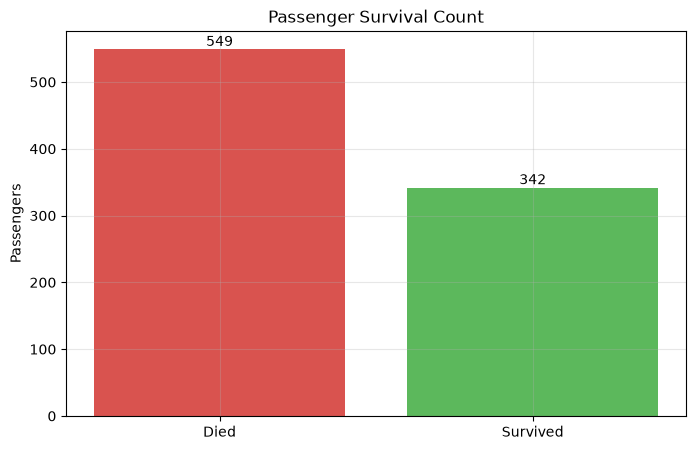

In [17]:
counts = df_clean["Survived"].value_counts().sort_index()
fig, ax = plt.subplots()
bars = ax.bar(["Died", "Survived"], counts.values, color=["#d9534f", "#5cb85c"])
ax.bar_label(bars)
ax.set_title("Passenger Survival Count")
ax.set_ylabel("Passengers")
plt.show()

### Viz 2 — Survival Rate by Class and Sex

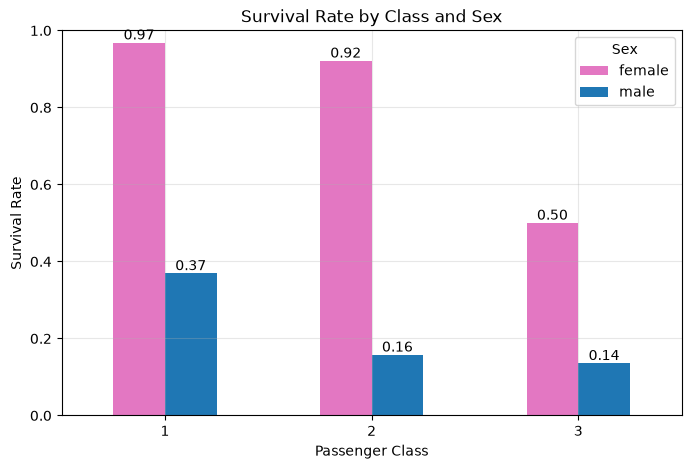

In [18]:
rate = df_clean.pivot_table(values="Survived", index="Pclass", columns="Sex", aggfunc="mean")
ax = rate.plot(kind="bar", color=["#e377c2", "#1f77b4"], rot=0)
ax.set_title("Survival Rate by Class and Sex")
ax.set_ylabel("Survival Rate")
ax.set_xlabel("Passenger Class")
ax.set_ylim(0, 1)
for c in ax.containers:
    ax.bar_label(c, fmt="%.2f")
plt.show()


### Viz 3 — Age Distribution by Survival

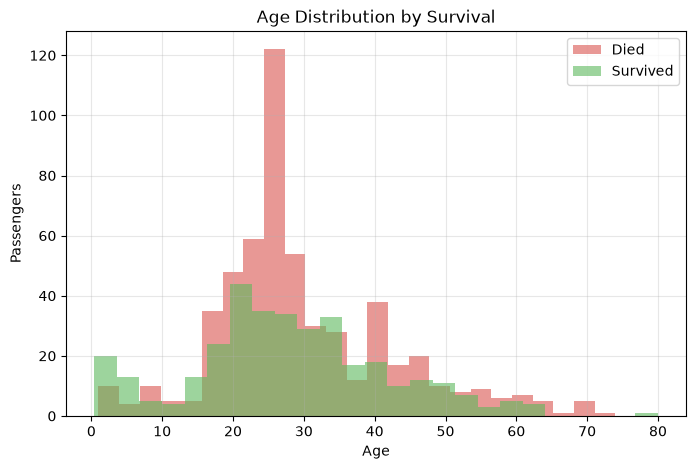

In [19]:
fig, ax = plt.subplots()
ax.hist(df_clean.loc[df_clean.Survived == 0, "Age"], bins=25, alpha=0.6, label="Died", color="#d9534f")
ax.hist(df_clean.loc[df_clean.Survived == 1, "Age"], bins=25, alpha=0.6, label="Survived", color="#5cb85c")
ax.set_title("Age Distribution by Survival")
ax.set_xlabel("Age")
ax.set_ylabel("Passengers")
ax.legend()
plt.show()

### Viz 4 — Fare by Class (Boxplot, shows outliers)

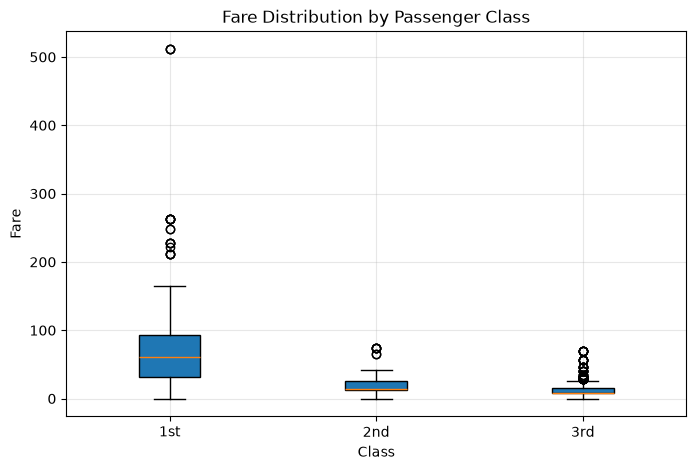

In [20]:
groups = [df_clean.loc[df_clean.Pclass == p, "Fare"] for p in [1, 2, 3]]
fig, ax = plt.subplots()
ax.boxplot(groups, patch_artist=True)
ax.set_xticks([1, 2, 3])
ax.set_xticklabels(["1st", "2nd", "3rd"])
ax.set_title("Fare Distribution by Passenger Class")
ax.set_xlabel("Class")
ax.set_ylabel("Fare")
plt.show()

### Viz 5 — Survival Rate by Family Size

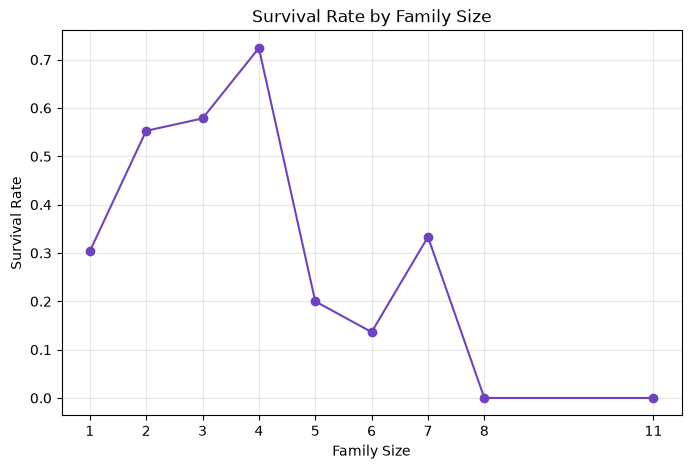

In [21]:
fam = df_clean.groupby("FamilySize")["Survived"].mean()
fig, ax = plt.subplots()
ax.plot(fam.index, fam.values, marker="o", color="#6f42c1")
ax.set_title("Survival Rate by Family Size")
ax.set_xlabel("Family Size")
ax.set_ylabel("Survival Rate")
ax.set_xticks(fam.index)
plt.show()

### Viz 6 — Survival Rate by Age Group

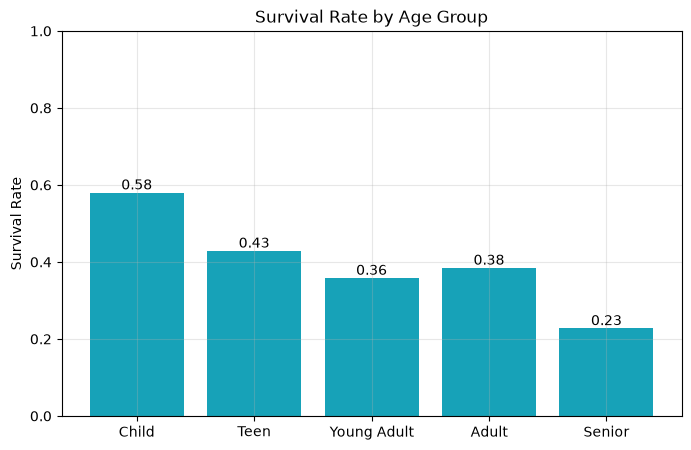

In [22]:
age_rate = df_clean.groupby("AgeGroup", observed=True)["Survived"].mean()
fig, ax = plt.subplots()
bars = ax.bar(age_rate.index.astype(str), age_rate.values, color="#17a2b8")
ax.bar_label(bars, fmt="%.2f")
ax.set_title("Survival Rate by Age Group")
ax.set_ylabel("Survival Rate")
ax.set_ylim(0, 1)
plt.show()

### Viz 7 — Correlation Heatmap

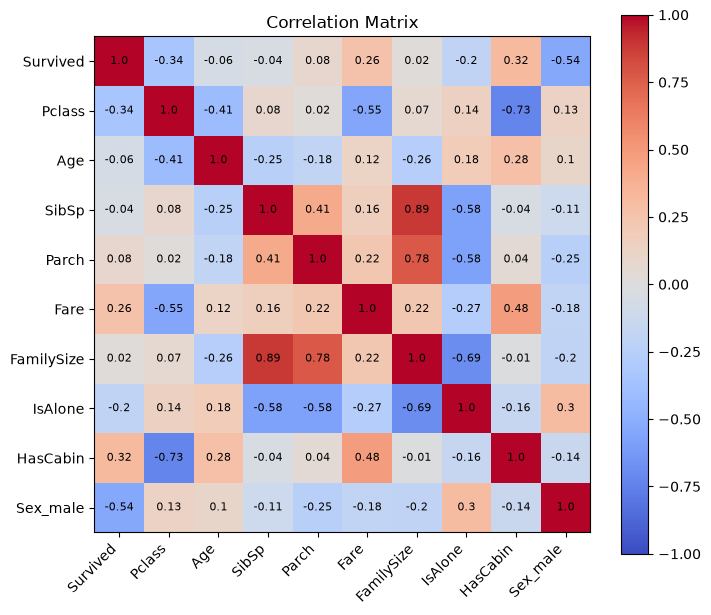

In [23]:
fig, ax = plt.subplots(figsize=(8, 7))
im = ax.imshow(corr.values, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr.columns)))
ax.set_yticks(range(len(corr.columns)))
ax.set_xticklabels(corr.columns, rotation=45, ha="right")
ax.set_yticklabels(corr.columns)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, corr.values[i, j], ha="center", va="center", fontsize=8)
ax.grid(False)
fig.colorbar(im)
ax.set_title("Correlation Matrix")
plt.show()

### Viz 8 — Age vs Fare (Scatter)

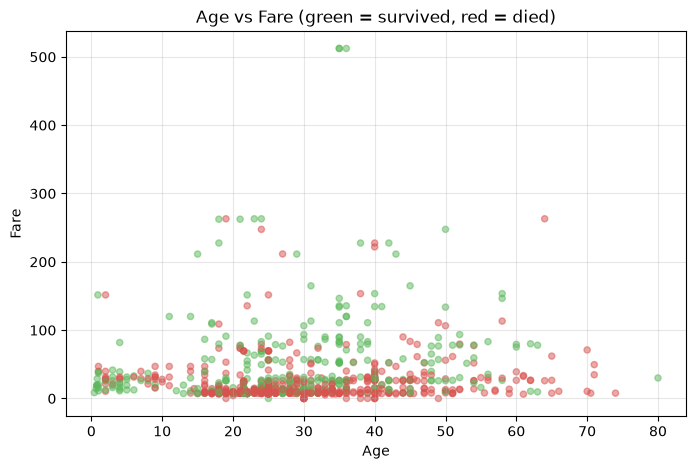

In [24]:
fig, ax = plt.subplots()
colors = df_clean["Survived"].map({0: "#d9534f", 1: "#5cb85c"})
ax.scatter(df_clean["Age"], df_clean["Fare"], c=colors, alpha=0.5, s=20)
ax.set_title("Age vs Fare (green = survived, red = died)")
ax.set_xlabel("Age")
ax.set_ylabel("Fare")
plt.show()

## 9) Anomaly Detection


In [25]:
def iqr_outliers(s):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    return s[(s < lo) | (s > hi)], lo, hi

for col in ["Fare", "Age"]:
    out, lo, hi = iqr_outliers(df_clean[col])
    print(f"{col}: {len(out)} outliers ({len(out)/len(df_clean):.1%}) | bounds = [{lo:.2f}, {hi:.2f}]")

print()
df_clean.nlargest(5, "Fare")[["Name", "Pclass", "Fare", "Survived"]]

Fare: 116 outliers (13.0%) | bounds = [-26.72, 65.63]
Age: 33 outliers (3.7%) | bounds = [-0.25, 57.75]



,Name,Pclass,Fare,Survived
258,"Ward, Miss. Anna",1,512.3292,1
679,"Cardeza, Mr. Thomas Drake Martinez",1,512.3292,1
737,"Lesurer, Mr. Gustave J",1,512.3292,1
27,"Fortune, Mr. Charles Alexander",1,263.0000,0
88,"Fortune, Miss. Mabel Helen",1,263.0000,1


## 10) Insights and Recommendations

### Key Insights
1. **Sex is the strongest factor** in survival: women survived at 74.2% versus 18.9% for men, consistent with the "women and children first" policy.
2. **Passenger class** is negatively correlated with survival: first class survived at 63.0%, second at 47.3%, third at 24.2%, reflecting unequal access to lifeboats.
3. **Children** had the highest survival rate among age groups (58.0%), while seniors had the lowest (22.7%).
4. **Travelling alone** was associated with lower survival (30.4%) compared with travelling with family (50.6%).
5. **Fare** has extreme high outliers (first-class tickets) and is positively correlated with survival (r = 0.26).
6. **Having a recorded cabin** is linked to much higher survival (66.7% vs 30.0%), mostly because it is a proxy for first class.
7. **Port of embarkation**: passengers from Cherbourg (C) survived more (55.4%) than those from Southampton (33.9%), partly because more first-class passengers boarded there.

### Recommendations
- **Predictive modeling:** the most useful features are `Sex`, `Pclass`, `Fare`, `Age/AgeGroup`, `FamilySize`, `IsAlone` and `Title`.
- **Data quality:** complete Cabin and Age records would improve the analysis (Cabin is more than 70% missing).
- **Outlier handling:** apply a log transform or capping to `Fare` before building any model.
- **Safety and emergency planning:** ensure equal access to evacuation resources across all classes, and give extra support to solo travelers and elderly passengers.
- **Next step:** train a Logistic Regression or Decision Tree on the engineered features and measure its accuracy.